# Cost-Sensitive Corporate Bankruptcy Risk Prediction

This project compares logistic regression and a compact Keras neural
network on a historical bankruptcy dataset. It investigates class
weighting and classification thresholds under hypothetical error costs.

The study is a historical benchmark comparison, not a model validated
for current lending or investment decisions.

## Experimental design

The dataset contains 6,819 observations, 95 predictors and 220 bankruptcy labels. A fixed-seed stratified split assigns 70% of observations to training, 15% to validation and 15% to testing. StandardScaler is fitted on training data only.

The comparison includes a no-skill baseline, logistic regression, and identical Keras MLPs trained with and without balanced class weights. Both MLPs use 64 and 32 ReLU units, Dropout(0.3), a sigmoid output, binary cross-entropy and Adam.

EarlyStopping monitors Keras validation PR-AUC with patience 10 and restores the best weights. Formal model comparison uses Average Precision (AP), computed consistently with scikit-learn. The weighted MLP is selected using validation AP. Thresholds for hypothetical FN:FP cost ratios of 2:1, 5:1 and 10:1 are selected on validation data and applied unchanged to test data.

In [1]:
from pathlib import Path
import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Keras version:", keras.__version__)

Project folder: /Users/kaya/Desktop/DATAX504-kaya/final_project
Keras version: 3.15.0


In [2]:
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/572/"
    "taiwanese%2Bbankruptcy%2Bprediction.zip"
)
csv_path = DATA_DIR / "data.csv"

# Download once; reuse the local file on later runs
if not csv_path.exists():
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        archive_bytes = response.read()

    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        csv_members = [
            name for name in archive.namelist()
            if Path(name).name == "data.csv"
        ]
        if len(csv_members) != 1:
            raise ValueError("Expected exactly one data.csv in the archive.")

        csv_path.write_bytes(archive.read(csv_members[0]))

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (6819, 96)


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


Missing values: 0
Duplicate rows: 0
Non-numeric columns: []

Class counts:
Bankrupt?
0    6599
1     220
Name: count, dtype: int64

Bankruptcy rate: 3.23%
Always predict non-bankrupt accuracy: 96.77%


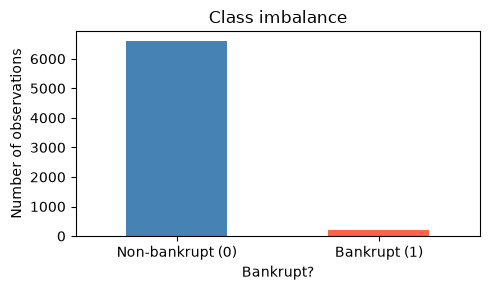

In [3]:
TARGET = "Bankrupt?"

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Non-numeric columns:",
      df.select_dtypes(exclude="number").columns.tolist())

class_counts = df[TARGET].value_counts().sort_index()
print("\nClass counts:")
print(class_counts)

bankruptcy_rate = df[TARGET].mean()
print(f"\nBankruptcy rate: {bankruptcy_rate:.2%}")
print(f"Always predict non-bankrupt accuracy: {1 - bankruptcy_rate:.2%}")

class_counts.plot.bar(
    figsize=(5, 3),
    color=["steelblue", "tomato"]
)
plt.xticks(
    [0, 1],
    ["Non-bankrupt (0)", "Bankrupt (1)"],
    rotation=0
)
plt.ylabel("Number of observations")
plt.title("Class imbalance")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

# Separate financial features from the bankruptcy label
X = df.drop(columns=[TARGET])
y = df[TARGET].astype("int32")

# Reserve 30% for validation and test
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

# Divide the reserved portion equally: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Observations": len(labels),
        "Bankrupt": int(labels.sum()),
        "Bankruptcy rate": labels.mean()
    }
    for name, labels in [
        ("Train", y_train),
        ("Validation", y_val),
        ("Test", y_test)
    ]
])

display(
    split_summary.style.format({
        "Bankruptcy rate": "{:.2%}"
    })
)

# Check that no original row appears in multiple splits
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(df)

print("Split checks passed.")

,Split,Observations,Bankrupt,Bankruptcy rate
0,Train,4773,154,3.23%
1,Validation,1023,33,3.23%
2,Test,1023,33,3.23%


Split checks passed.


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn means and standard deviations from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to validation data
X_val_scaled = scaler.transform(X_val)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("All training values finite:",
      np.isfinite(X_train_scaled).all())
print("All validation values finite:",
      np.isfinite(X_val_scaled).all())

Training shape: (4773, 95)
Validation shape: (1023, 95)
All training values finite: True
All validation values finite: True


In [6]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    random_state=SEED
)

logistic_model.fit(X_train_scaled, y_train)

# Probability assigned to the bankrupt class
logistic_val_prob = logistic_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Training completed.")
print("Iterations:", logistic_model.n_iter_[0])
print("First five validation risk scores:",
      np.round(logistic_val_prob[:5], 4))

Training completed.
Iterations: 63
First five validation risk scores: [0.     0.0066 0.0528 0.1035 0.0014]


,Model,PR-AUC (AP),ROC-AUC
0,No-skill,0.0323,0.5000
1,Logistic Regression,0.2587,0.8766


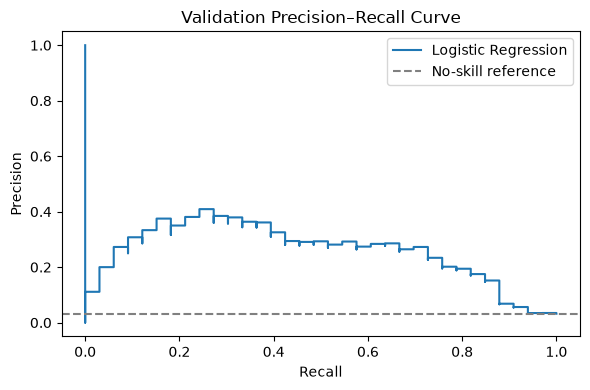

In [7]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)

# Assign the same training-class prevalence to every observation
no_skill_val_prob = np.full(
    len(y_val),
    y_train.mean()
)

validation_results = [
    {
        "Model": "No-skill",
        "PR-AUC (AP)": average_precision_score(
            y_val, no_skill_val_prob
        ),
        "ROC-AUC": roc_auc_score(
            y_val, no_skill_val_prob
        )
    },
    {
        "Model": "Logistic Regression",
        "PR-AUC (AP)": average_precision_score(
            y_val, logistic_val_prob
        ),
        "ROC-AUC": roc_auc_score(
            y_val, logistic_val_prob
        )
    }
]

display(
    pd.DataFrame(validation_results).style.format({
        "PR-AUC (AP)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

precision, recall, _ = precision_recall_curve(
    y_val, logistic_val_prob
)

plt.figure(figsize=(6, 4))
plt.step(
    recall, precision,
    where="post",
    label="Logistic Regression"
)
plt.axhline(
    y_val.mean(),
    color="grey",
    linestyle="--",
    label="No-skill reference"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision–Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Use float32 arrays for neural-network training
X_train_nn = X_train_scaled.astype("float32")
X_val_nn = X_val_scaled.astype("float32")

y_train_nn = y_train.to_numpy(dtype="float32")
y_val_nn = y_val.to_numpy(dtype="float32")


def build_mlp():
    model = keras.Sequential([
        keras.Input(shape=(X_train_nn.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(
                curve="PR",
                name="pr_auc",
                num_thresholds=1000
            )
        ]
    )

    return model


keras.utils.set_random_seed(SEED)
mlp_plain = build_mlp()
mlp_plain.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,257 (32.25 KB)

 Trainable params: 8,257 (32.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stopping_plain = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True
)

history_plain = mlp_plain.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=100,
    batch_size=64,
    shuffle=True,
    callbacks=[early_stopping_plain],
    verbose=2
)

Epoch 1/100
75/75 - 0s - 6ms/step - loss: 0.3679 - pr_auc: 0.0350 - val_loss: 0.2959 - val_pr_auc: 0.1238
Epoch 2/100
75/75 - 0s - 546us/step - loss: 0.1351 - pr_auc: 0.2082 - val_loss: 0.2949 - val_pr_auc: 0.2413
Epoch 3/100
75/75 - 0s - 526us/step - loss: 0.1072 - pr_auc: 0.3293 - val_loss: 0.2911 - val_pr_auc: 0.2557
Epoch 4/100
75/75 - 0s - 523us/step - loss: 0.0987 - pr_auc: 0.3474 - val_loss: 0.2889 - val_pr_auc: 0.2504
Epoch 5/100
75/75 - 0s - 514us/step - loss: 0.0921 - pr_auc: 0.3998 - val_loss: 0.2946 - val_pr_auc: 0.2581
Epoch 6/100
75/75 - 0s - 513us/step - loss: 0.0849 - pr_auc: 0.4457 - val_loss: 0.3080 - val_pr_auc: 0.2542
Epoch 7/100
75/75 - 0s - 511us/step - loss: 0.0853 - pr_auc: 0.4467 - val_loss: 0.3109 - val_pr_auc: 0.2555
Epoch 8/100
75/75 - 0s - 504us/step - loss: 0.0830 - pr_auc: 0.4288 - val_loss: 0.3269 - val_pr_auc: 0.2416
Epoch 9/100
75/75 - 0s - 507us/step - loss: 0.0832 - pr_auc: 0.4693 - val_loss: 0.3478 - val_pr_auc: 0.2447
Epoch 10/100
75/75 - 0s - 506u

,Model,PR-AUC (AP),ROC-AUC
0,No-skill,0.0323,0.5000
1,Logistic Regression,0.2587,0.8766
2,MLP without class weights,0.2730,0.8415


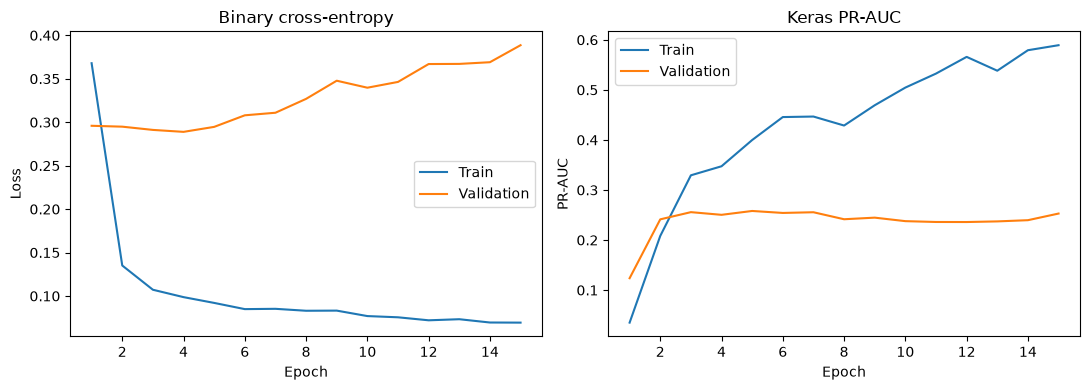

In [10]:
mlp_plain_val_prob = mlp_plain.predict(
    X_val_nn,
    verbose=0
).ravel()

plain_result = {
    "Model": "MLP without class weights",
    "PR-AUC (AP)": average_precision_score(
        y_val, mlp_plain_val_prob
    ),
    "ROC-AUC": roc_auc_score(
        y_val, mlp_plain_val_prob
    )
}

# Update the table without creating duplicates if this cell is rerun
validation_results = [
    row for row in validation_results
    if row["Model"] != plain_result["Model"]
]
validation_results.append(plain_result)

display(
    pd.DataFrame(validation_results).style.format({
        "PR-AUC (AP)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

epochs_run = range(1, len(history_plain.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    epochs_run, history_plain.history["loss"], label="Train"
)
axes[0].plot(
    epochs_run, history_plain.history["val_loss"], label="Validation"
)
axes[0].set_title("Binary cross-entropy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    epochs_run, history_plain.history["pr_auc"], label="Train"
)
axes[1].plot(
    epochs_run, history_plain.history["val_pr_auc"], label="Validation"
)
axes[1].set_title("Keras PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

In [11]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.to_numpy()
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Class weights:", class_weights)
print(
    "Bankrupt / non-bankrupt weight ratio:",
    class_weights[1] / class_weights[0]
)

Class weights: {0: 0.5166702749512881, 1: 15.496753246753247}
Bankrupt / non-bankrupt weight ratio: 29.993506493506494


In [12]:
# Start a fresh model using the same architecture and random seed
keras.utils.set_random_seed(SEED)
mlp_weighted = build_mlp()

early_stopping_weighted = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True
)

history_weighted = mlp_weighted.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=100,
    batch_size=64,
    shuffle=True,
    class_weight=class_weights,
    callbacks=[early_stopping_weighted],
    verbose=2
)

Epoch 1/100
75/75 - 0s - 6ms/step - loss: 0.5376 - pr_auc: 0.2289 - val_loss: 0.5203 - val_pr_auc: 0.2723
Epoch 2/100
75/75 - 0s - 546us/step - loss: 0.4087 - pr_auc: 0.3119 - val_loss: 0.4703 - val_pr_auc: 0.2561
Epoch 3/100
75/75 - 0s - 522us/step - loss: 0.3711 - pr_auc: 0.3282 - val_loss: 0.4842 - val_pr_auc: 0.2528
Epoch 4/100
75/75 - 0s - 518us/step - loss: 0.3352 - pr_auc: 0.3889 - val_loss: 0.4684 - val_pr_auc: 0.2461
Epoch 5/100
75/75 - 0s - 520us/step - loss: 0.3089 - pr_auc: 0.3884 - val_loss: 0.4970 - val_pr_auc: 0.2469
Epoch 6/100
75/75 - 0s - 522us/step - loss: 0.2908 - pr_auc: 0.4094 - val_loss: 0.4696 - val_pr_auc: 0.2521
Epoch 7/100
75/75 - 0s - 508us/step - loss: 0.2852 - pr_auc: 0.4172 - val_loss: 0.4631 - val_pr_auc: 0.2608
Epoch 8/100
75/75 - 0s - 511us/step - loss: 0.2725 - pr_auc: 0.4109 - val_loss: 0.5146 - val_pr_auc: 0.2616
Epoch 9/100
75/75 - 0s - 509us/step - loss: 0.2614 - pr_auc: 0.4403 - val_loss: 0.4699 - val_pr_auc: 0.2423
Epoch 10/100
75/75 - 0s - 512u

,Model,PR-AUC (AP),ROC-AUC
0,No-skill,0.0323,0.5000
1,Logistic Regression,0.2587,0.8766
2,MLP without class weights,0.2730,0.8415
3,MLP with class weights,0.2819,0.8683


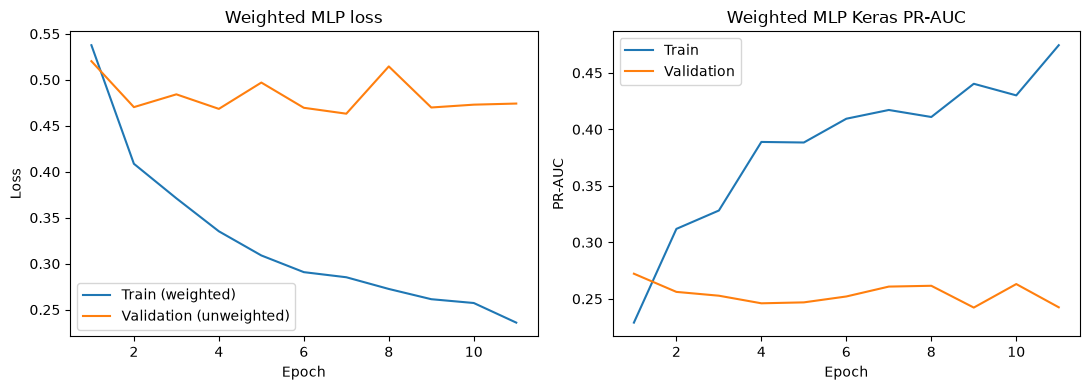

In [13]:
mlp_weighted_val_prob = mlp_weighted.predict(
    X_val_nn,
    verbose=0
).ravel()

weighted_result = {
    "Model": "MLP with class weights",
    "PR-AUC (AP)": average_precision_score(
        y_val, mlp_weighted_val_prob
    ),
    "ROC-AUC": roc_auc_score(
        y_val, mlp_weighted_val_prob
    )
}

validation_results = [
    row for row in validation_results
    if row["Model"] != weighted_result["Model"]
]
validation_results.append(weighted_result)

display(
    pd.DataFrame(validation_results).style.format({
        "PR-AUC (AP)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

epochs_run = range(1, len(history_weighted.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    epochs_run, history_weighted.history["loss"],
    label="Train (weighted)"
)
axes[0].plot(
    epochs_run, history_weighted.history["val_loss"],
    label="Validation (unweighted)"
)
axes[0].set_title("Weighted MLP loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    epochs_run, history_weighted.history["pr_auc"],
    label="Train"
)
axes[1].plot(
    epochs_run, history_weighted.history["val_pr_auc"],
    label="Validation"
)
axes[1].set_title("Weighted MLP Keras PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

In [14]:
selected_model = mlp_weighted
selected_model_name = "MLP with class weights"
selected_val_prob = mlp_weighted_val_prob.copy()

print("Selected model:", selected_model_name)
print(
    "Validation AP:",
    average_precision_score(y_val, selected_val_prob)
)

Selected model: MLP with class weights
Validation AP: 0.2819219945705327


In [15]:
from sklearn.metrics import confusion_matrix

def evaluate_threshold(y_true, scores, threshold, fn_cost):
    predictions = (scores >= threshold).astype("int32")

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Threshold": float(threshold),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Precision": tp / (tp + fp) if tp + fp else 0.0,
        "Recall": tp / (tp + fn) if tp + fn else 0.0,
        "Alerts": int(tp + fp),
        "Cost": int(fn_cost * fn + fp)
    }


# Check every threshold where the predicted classifications can change
# The final candidate allows an "alert nobody" decision
candidate_thresholds = np.unique(np.r_[
    0.0,
    selected_val_prob,
    np.nextafter(float(selected_val_prob.max()), np.inf)
])

selected_thresholds = {}
threshold_results = []

for ratio in [2, 5, 10]:
    candidates = pd.DataFrame([
        evaluate_threshold(
            y_val, selected_val_prob, threshold, ratio
        )
        for threshold in candidate_thresholds
    ])

    # If costs tie, prefer fewer false alarms;
    # then prefer the higher threshold
    best = candidates.sort_values(
        ["Cost", "FP", "Threshold"],
        ascending=[True, True, False]
    ).iloc[0]

    threshold = float(best["Threshold"])
    selected_thresholds[ratio] = threshold

    for rule, value in [
        ("Default 0.5", 0.5),
        ("Validation-selected", threshold)
    ]:
        result = evaluate_threshold(
            y_val, selected_val_prob, value, ratio
        )
        result.update({
            "FN:FP cost ratio": f"{ratio}:1",
            "Rule": rule
        })
        threshold_results.append(result)

threshold_table = pd.DataFrame(threshold_results)

columns = [
    "FN:FP cost ratio", "Rule", "Threshold",
    "TP", "FP", "FN", "TN",
    "Precision", "Recall", "Alerts", "Cost"
]

display(
    threshold_table[columns].style.format({
        "Threshold": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,FN:FP cost ratio,Rule,Threshold,TP,FP,FN,TN,Precision,Recall,Alerts,Cost
0,2:1,Default 0.5,0.5000,29,252,4,738,10.32%,87.88%,281,260
1,2:1,Validation-selected,0.8948,8,12,25,978,40.00%,24.24%,20,62
2,5:1,Default 0.5,0.5000,29,252,4,738,10.32%,87.88%,281,272
3,5:1,Validation-selected,0.7350,20,47,13,943,29.85%,60.61%,67,112
4,10:1,Default 0.5,0.5000,29,252,4,738,10.32%,87.88%,281,292
5,10:1,Validation-selected,0.6771,23,71,10,919,24.47%,69.70%,94,171


In [16]:
# Apply the scaler already fitted on training data
X_test_scaled = scaler.transform(X_test)
X_test_nn = X_test_scaled.astype("float32")

test_probabilities = {
    "No-skill": np.full(len(y_test), y_train.mean()),
    "Logistic Regression": logistic_model.predict_proba(
        X_test_scaled
    )[:, 1],
    "MLP without class weights": mlp_plain.predict(
        X_test_nn, verbose=0
    ).ravel(),
    "MLP with class weights": selected_model.predict(
        X_test_nn, verbose=0
    ).ravel()
}

test_results = []

for name, probabilities in test_probabilities.items():
    test_results.append({
        "Model": name,
        "Test AP": average_precision_score(
            y_test, probabilities
        ),
        "Test ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

test_results_table = pd.DataFrame(test_results)

display(
    test_results_table.style.format({
        "Test AP": "{:.4f}",
        "Test ROC-AUC": "{:.4f}"
    })
)

,Model,Test AP,Test ROC-AUC
0,No-skill,0.0323,0.5000
1,Logistic Regression,0.2943,0.9015
2,MLP without class weights,0.3135,0.8160
3,MLP with class weights,0.3145,0.8569


In [17]:
selected_test_prob = test_probabilities[selected_model_name]

test_threshold_results = []

for ratio in [2, 5, 10]:
    for rule, threshold in [
        ("Default 0.5", 0.5),
        ("Validation-selected", selected_thresholds[ratio])
    ]:
        result = evaluate_threshold(
            y_test,
            selected_test_prob,
            threshold,
            ratio
        )

        result.update({
            "FN:FP cost ratio": f"{ratio}:1",
            "Rule": rule,
            "No-alert cost": int(ratio * y_test.sum())
        })

        test_threshold_results.append(result)

test_threshold_table = pd.DataFrame(test_threshold_results)

test_columns = [
    "FN:FP cost ratio", "Rule", "Threshold",
    "TP", "FP", "FN", "TN",
    "Precision", "Recall", "Alerts",
    "Cost", "No-alert cost"
]

display(
    test_threshold_table[test_columns].style.format({
        "Threshold": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,FN:FP cost ratio,Rule,Threshold,TP,FP,FN,TN,Precision,Recall,Alerts,Cost,No-alert cost
0,2:1,Default 0.5,0.5000,28,239,5,751,10.49%,84.85%,267,249,66
1,2:1,Validation-selected,0.8948,6,7,27,983,46.15%,18.18%,13,61,66
2,5:1,Default 0.5,0.5000,28,239,5,751,10.49%,84.85%,267,264,165
3,5:1,Validation-selected,0.7350,16,40,17,950,28.57%,48.48%,56,125,165
4,10:1,Default 0.5,0.5000,28,239,5,751,10.49%,84.85%,267,289,330
5,10:1,Validation-selected,0.6771,19,71,14,919,21.11%,57.58%,90,211,330


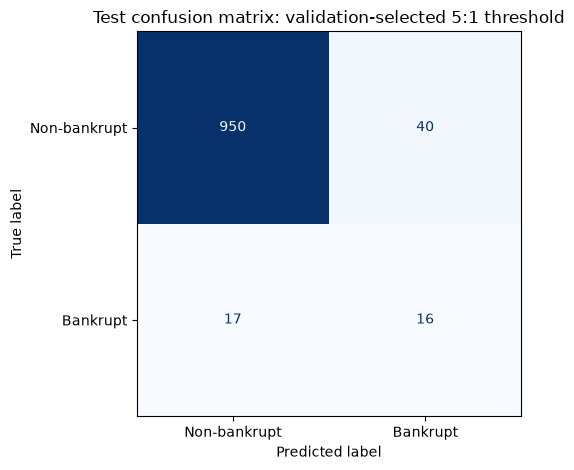

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

ANALYSIS_RATIO = 5
analysis_threshold = selected_thresholds[ANALYSIS_RATIO]

test_predictions = (
    selected_test_prob >= analysis_threshold
).astype("int32")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Non-bankrupt", "Bankrupt"],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Test confusion matrix: validation-selected 5:1 threshold")
plt.tight_layout()
plt.show()

In [19]:
error_analysis = pd.DataFrame({
    "True label": y_test.to_numpy(),
    "Risk score": selected_test_prob,
    "Predicted label": test_predictions
}, index=X_test.index)

error_analysis.index.name = "Original row"

error_analysis["Outcome"] = np.select(
    [
        (error_analysis["True label"] == 1)
        & (error_analysis["Predicted label"] == 1),

        (error_analysis["True label"] == 1)
        & (error_analysis["Predicted label"] == 0),

        (error_analysis["True label"] == 0)
        & (error_analysis["Predicted label"] == 1)
    ],
    ["TP", "FN", "FP"],
    default="TN"
)

print(error_analysis["Outcome"].value_counts())

Outcome
TN    950
FP     40
FN     17
TP     16
Name: count, dtype: int64


In [20]:
financial_features = [
    "ROA(A) before interest and % after tax",
    "Debt ratio %",
    "Working Capital to Total Assets",
    "Cash Flow to Total Assets"
]

missing_features = [
    name for name in financial_features
    if name not in X_test.columns
]
if missing_features:
    raise ValueError(f"Check feature names: {missing_features}")

# Missed bankrupt observations with the lowest risk scores
fn_examples = (
    error_analysis[error_analysis["Outcome"] == "FN"]
    .sort_values("Risk score")
    .head(3)
)

# Non-bankrupt observations with the highest risk scores
fp_examples = (
    error_analysis[error_analysis["Outcome"] == "FP"]
    .sort_values("Risk score", ascending=False)
    .head(3)
)

print("False negatives: lowest-scored bankrupt observations")
display(
    fn_examples.join(X_test[financial_features])
)

print("False positives: highest-scored non-bankrupt observations")
display(
    fp_examples.join(X_test[financial_features])
)

False negatives: lowest-scored bankrupt observations


,True label,Risk score,Predicted label,Outcome,ROA(A) before interest and % after tax,Debt ratio %,Working Capital to Total Assets,Cash Flow to Total Assets
Original row,,,,,,,,
379,1,0.000000,0,FN,0.516082,0.246576,0.669428,0.642172
1870,1,0.019327,0,FN,0.314708,0.326934,0.709948,0.634720
1953,1,0.229087,0,FN,0.508395,0.127249,0.803201,0.637456


False positives: highest-scored non-bankrupt observations


,True label,Risk score,Predicted label,Outcome,ROA(A) before interest and % after tax,Debt ratio %,Working Capital to Total Assets,Cash Flow to Total Assets
Original row,,,,,,,,
2605,0,0.999576,1,FP,0.479503,0.159628,0.612860,0.448263
2843,0,0.997911,1,FP,0.568742,0.067449,0.750469,0.641441
5033,0,0.994110,1,FP,0.263792,0.241920,0.625176,0.635033


In [21]:
# Combine the six examples already selected
case_ids = fn_examples.index.tolist() + fp_examples.index.tolist()

case_summary = error_analysis.loc[case_ids].copy()

# Check whether any standardized input is unusually large
test_scaled_df = pd.DataFrame(
    X_test_scaled,
    index=X_test.index,
    columns=X_test.columns
)

case_summary["Max absolute standardized feature"] = (
    test_scaled_df.loc[case_ids].abs().max(axis=1)
)

display(
    case_summary.style.format({
        "Risk score": "{:.6e}",
        "Max absolute standardized feature": "{:.2f}"
    })
)

# Position of each financial indicator within the training distribution
percentile_table = pd.DataFrame(index=case_ids)

for feature in financial_features:
    training_values = X_train[feature].to_numpy()

    percentile_table[feature] = [
        100 * np.mean(
            training_values <= X_test.loc[row_id, feature]
        )
        for row_id in case_ids
    ]

percentile_table.index.name = "Original row"

print("Feature percentiles relative to training data:")
display(percentile_table.style.format("{:.1f}"))

,True label,Risk score,Predicted label,Outcome,Max absolute standardized feature
Original row,,,,,
379,1,0.000000e+00,0,FN,127186125800.13
1870,1,1.932697e-02,0,FN,34.53
1953,1,2.290870e-01,0,FN,14.22
2605,0,9.995761e-01,1,FP,129.23
2843,0,9.979107e-01,1,FP,135.54
5033,0,9.941098e-01,1,FP,11.30


Feature percentiles relative to training data:


,ROA(A) before interest and % after tax,Debt ratio %,Working Capital to Total Assets,Cash Flow to Total Assets
Original row,,,,
379,16.7,99.4,0.5,41.4
1870,0.8,100.0,2.7,26.8
1953,14.6,61.1,45.3,30.9
2605,8.3,80.9,0.1,0.3
2843,60.0,21.9,11.0,39.4
5033,0.4,99.1,0.1,27.3


At the validation-selected threshold for the hypothetical 5:1 cost ratio, the model detected 16 of the 33 bankrupt test observations and missed 17. It generated 40 false alarms, giving a precision of 28.57% and recall of 48.48%. The scenario cost was 125, compared with 264 at the default threshold and 165 when issuing no alerts.

The inspected cases included bankrupt observations assigned very low scores and non-bankrupt observations assigned scores close to one. These confident errors show that the outputs should be treated as model scores rather than calibrated bankruptcy probabilities. The four displayed financial indicators provide descriptive context but do not explain the full model, which uses 95 features. These deliberately selected extreme errors are illustrative and are not representative of every misclassified observation.

In [22]:
# Confirm that the scaler still belongs to the training split
assert list(scaler.feature_names_in_) == list(X_train.columns)
assert list(X_test.columns) == list(X_train.columns)
assert np.allclose(
    scaler.mean_,
    X_train.mean().to_numpy()
)

row_id = 379

# Identify the five most extreme standardized features
largest_features = (
    test_scaled_df.loc[row_id]
    .abs()
    .nlargest(5)
    .index
)

diagnostic_rows = []

for feature in largest_features:
    column_position = X_train.columns.get_loc(feature)
    training_values = X_train[feature]

    diagnostic_rows.append({
        "Feature": feature,
        "Test raw value": X_test.loc[row_id, feature],
        "Train minimum": training_values.min(),
        "Train median": training_values.median(),
        "Train maximum": training_values.max(),
        "Train mean": scaler.mean_[column_position],
        "Scaler scale": scaler.scale_[column_position],
        "Train unique values": training_values.nunique(),
        "Test standardized value":
            test_scaled_df.loc[row_id, feature]
    })

diagnostic_table = pd.DataFrame(diagnostic_rows)

numeric_columns = [
    "Test raw value",
    "Train minimum",
    "Train median",
    "Train maximum",
    "Train mean",
    "Scaler scale",
    "Test standardized value"
]

display(
    diagnostic_table.style.format({
        column: "{:.4e}"
        for column in numeric_columns
    })
)

print("Scaler checks passed.")

,Feature,Test raw value,Train minimum,Train median,Train maximum,Train mean,Scaler scale,Train unique values,Test standardized value
0,Revenue per person,7.0500e+09,0.0000e+00,1.8442e-02,1.0000e+00,3.5116e-02,5.5431e-02,4160,1.2719e+11
1,No-credit Interval,6.7935e-01,0.0000e+00,6.2388e-01,1.0000e+00,6.2376e-01,1.2687e-02,4773,4.3815e+00
2,After-tax net Interest Rate,7.6155e-01,8.4286e-02,8.0937e-01,1.0000e+00,8.0919e-01,1.0915e-02,2893,-4.3642e+00
3,Accounts Receivable Turnover,1.2200e+09,0.0000e+00,9.6984e-04,9.7400e+09,1.3554e+07,3.0078e+08,1367,4.0111e+00
4,Working capitcal Turnover Rate,5.7289e-01,5.9314e-01,5.9396e-01,1.0000e+00,5.9411e-01,6.0853e-03,4773,-3.4869e+00


Scaler checks passed.


In [23]:
row_id = 379
feature = "Revenue per person"

# Create a diagnostic copy of this observation
probe = X_test.loc[[row_id]].copy()
original_value = probe.loc[row_id, feature]
replacement_value = X_train[feature].median()

probe.loc[row_id, feature] = replacement_value

probe_scaled = scaler.transform(probe).astype("float32")
probe_score = float(
    selected_model.predict(probe_scaled, verbose=0).ravel()[0]
)

sensitivity_result = pd.DataFrame([
    {
        "Input": "Original test observation",
        "Revenue per person": original_value,
        "Risk score": error_analysis.loc[row_id, "Risk score"]
    },
    {
        "Input": "Diagnostic copy: training median substituted",
        "Revenue per person": replacement_value,
        "Risk score": probe_score
    }
])

display(
    sensitivity_result.style.format({
        "Revenue per person": "{:.6e}",
        "Risk score": "{:.6e}"
    })
)

,Input,Revenue per person,Risk score
0,Original test observation,7.050000e+09,0.000000e+00
1,Diagnostic copy: training median substituted,1.844220e-02,9.624930e-01


A sensitivity check identified an extreme input in false-negative observation 379. Its “Revenue per person” value was 7.05 × 10⁹, whereas this feature ranged from 0 to 1 in the training set. Applying the training-fitted StandardScaler produced a value of approximately 1.27 × 10¹¹.

In a diagnostic copy, replacing only this feature with its training median changed the model score from 0 to 0.9625, crossing the fixed 5:1 threshold of approximately 0.7350. This demonstrates strong sensitivity to this extreme input. However, the substituted value is hypothetical and does not establish the correct financial value or probability of bankruptcy. The original observation remains a false negative in all reported test metrics. Future work should investigate data consistency and preprocessing rules for extreme values, using training data to define those rules.

In [24]:
import json
import joblib
import sklearn

RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

# Save the trained models and training-fitted preprocessing
selected_model.save(MODELS_DIR / "mlp_weighted.keras")
joblib.dump(scaler, MODELS_DIR / "scaler.joblib")
joblib.dump(logistic_model, MODELS_DIR / "logistic_model.joblib")

# Save the original evaluation results
pd.DataFrame(validation_results).to_csv(
    RESULTS_DIR / "validation_metrics.csv", index=False
)
test_results_table.to_csv(
    RESULTS_DIR / "test_metrics.csv", index=False
)
threshold_table.to_csv(
    RESULTS_DIR / "validation_thresholds.csv", index=False
)
test_threshold_table.to_csv(
    RESULTS_DIR / "test_thresholds.csv", index=False
)
error_analysis.to_csv(
    RESULTS_DIR / "test_predictions.csv"
)
diagnostic_table.to_csv(
    RESULTS_DIR / "extreme_input_diagnostic.csv", index=False
)
sensitivity_result.to_csv(
    RESULTS_DIR / "input_sensitivity.csv", index=False
)

# Record the exact observations assigned to each split
split_rows = pd.concat([
    pd.DataFrame({"Original row": X_train.index, "Split": "Train"}),
    pd.DataFrame({"Original row": X_val.index, "Split": "Validation"}),
    pd.DataFrame({"Original row": X_test.index, "Split": "Test"})
], ignore_index=True)

split_rows.to_csv(
    RESULTS_DIR / "split_rows.csv", index=False
)

config = {
    "seed": SEED,
    "selected_model": selected_model_name,
    "primary_metric": "Average Precision (AP)",
    "thresholds": {
        str(ratio): float(threshold)
        for ratio, threshold in selected_thresholds.items()
    },
    "keras_version": keras.__version__,
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__
}

with open(RESULTS_DIR / "experiment_config.json", "w") as file:
    json.dump(config, file, indent=2)

print("Models saved to:", MODELS_DIR)
print("Results saved to:", RESULTS_DIR)

Models saved to: /Users/kaya/Desktop/DATAX504-kaya/final_project/models
Results saved to: /Users/kaya/Desktop/DATAX504-kaya/final_project/results


In [25]:
# Reload the saved preprocessing and neural network
loaded_scaler = joblib.load(MODELS_DIR / "scaler.joblib")
loaded_model = keras.models.load_model(
    MODELS_DIR / "mlp_weighted.keras",
    compile=False
)

# Verify on validation data
X_val_reloaded = loaded_scaler.transform(
    X_val
).astype("float32")

reloaded_val_prob = loaded_model.predict(
    X_val_reloaded,
    verbose=0
).ravel()

max_difference = np.max(
    np.abs(reloaded_val_prob - selected_val_prob)
)

print("Maximum prediction difference:", max_difference)

assert np.allclose(
    reloaded_val_prob,
    selected_val_prob,
    rtol=1e-5,
    atol=1e-6
)

print("Reload verification passed.")

Maximum prediction difference: 0.0
Reload verification passed.


In [26]:
# Use the previously analysed observation as a demo
DEMO_ROW = 379

with open(RESULTS_DIR / "experiment_config.json") as file:
    saved_config = json.load(file)

demo_threshold = saved_config["thresholds"]["5"]

demo_input = X_test.loc[[DEMO_ROW]]
demo_scaled = loaded_scaler.transform(
    demo_input
).astype("float32")

demo_score = float(
    loaded_model.predict(demo_scaled, verbose=0).ravel()[0]
)

demo_prediction = int(demo_score >= demo_threshold)

print("Original dataset row:", DEMO_ROW)
print("True label:", int(y_test.loc[DEMO_ROW]))
print(f"Model score: {demo_score:.6e}")
print(f"Fixed 5:1 threshold: {demo_threshold:.4f}")
print("Predicted label:", demo_prediction)

Original dataset row: 379
True label: 1
Model score: 0.000000e+00
Fixed 5:1 threshold: 0.7350
Predicted label: 0


This bankrupt observation received a score of zero and was missed by the model. Its revenue-per-person feature was far outside the training range. A separate sensitivity check showed that the prediction was strongly affected by this extreme input.

## Conclusion

The weighted MLP achieved test AP of 0.3145, compared with 0.3135 for the unweighted MLP and 0.2943 for logistic regression. The near-identical MLP results provide limited evidence of a benefit from class weighting in this single experiment. Logistic regression achieved the highest test ROC-AUC.

Validation-selected thresholds reduced hypothetical test costs relative to the default 0.5 threshold, while trading recall against false alarms. At the 5:1 threshold, the model detected 16 of 33 bankrupt observations and generated 40 false alarms.

An extreme input caused a confident false negative, demonstrating a weakness of the current preprocessing and model. Historical data, only 33 bankrupt test observations, a single split and seed, and hypothetical costs limit the conclusions. Future work should investigate data consistency, extreme-value handling and validation on newer data.

## AI assistance disclosure

| Field | Disclosure |
|---|---|
| Tool and model | ChatGPT and Codex (OpenAI) |
| Used for | Step-by-step code suggestions, explanations, interpretation of outputs, diagnostic suggestions, and drafting documentation and report text. |
| Verification performed | I ran the notebook locally from a restarted kernel, checked the split assertions and saved results, and verified that reloading the saved model reproduced validation predictions with a maximum difference of 0.0. |
| My own work | I entered and executed the code, inspected the outputs, and performed the local reproduction check. With reference to my own understanding, I compiled the final report with AI assistance and performed the final review. 
|